# Weather archive MAPE: old source vs. new source

Reviewer point A1 flagged a bug in `weather_forecast_backfill`: the code built its training data from Open-Meteo's Historical Forecast API, not a genuine archived forecast. That API stitches each model run's first few hours together with real measurements, so its values track the actual weather far more closely than a forecast issued 22-45 hours ahead ever could. The fix switched to the Single Runs API, which replays one specific model run exactly as it was issued.

The reviewers asked for a number, not just a changed data source. This notebook scores both the old source and the new one against ERA5 reanalysis, a third source that neither one reads from, over 14 days and 4 Swiss cities. It reports how far the old source understated the real forecast error.

In [1]:
import datetime as dt

import matplotlib.pyplot as plt
import pandas as pd
import requests

from winterload.config import PROJECT_ROOT
from winterload import COORDINATES
from winterload.source.openmeteo import HOURLY_VARIABLES, OpenMeteo

ZURICH_TZ = "Europe/Zurich"
# Two sample weeks, inside the Single Runs API's ECMWF IFS HRES coverage (from March 2024) and
# recent enough that ERA5 has already reprocessed these dates.
START_DATE = dt.date(2026, 10, 1)
END_DATE = dt.date(2026, 10, 14)

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
KELVIN_OFFSET = 273.15

## Matching hours across three sources

Each source reports timestamps in UTC. A "day" here means 24 local hours in Zurich, the same definition `weather_forecast_backfill` uses. These two helpers pick out exactly the rows that belong to one calendar day in `Europe/Zurich`, regardless of which API they came from.

In [2]:
def day_bounds(day: dt.date) -> tuple[pd.Timestamp, pd.Timestamp]:
    return pd.Timestamp(day, tz=ZURICH_TZ), pd.Timestamp(day + dt.timedelta(days=1), tz=ZURICH_TZ)


def clip_to_day(df: pd.DataFrame, day: dt.date) -> pd.DataFrame:
    start, end = day_bounds(day)
    return df.loc[(df["date"] >= start) & (df["date"] < end)].set_index("date")[HOURLY_VARIABLES]

## Ground truth: ERA5 reanalysis

`ground_truth` pulls the ERA5 reanalysis for the city and day from `archive-api.open-meteo.com`. ERA5 is a weather model too, not raw station readings, but it ingests the full record after the fact and never feeds into `weather_forecast_stats` or `weather_measurements_stats`. That independence matters: scoring the old source against the new source directly would only compare two forecasts to each other. Scoring both against a third party that neither one feeds shows which one actually comes closer to what happened.

In [3]:
def ground_truth(day: dt.date, lat: float, lon: float) -> pd.DataFrame:
    response = requests.get(ARCHIVE_URL, params={
        "latitude": lat, "longitude": lon,
        "start_date": (day - dt.timedelta(days=1)).isoformat(),
        "end_date": (day + dt.timedelta(days=1)).isoformat(),
        "hourly": HOURLY_VARIABLES,
        "models": "era5_seamless",
        "timezone": "UTC",
    }, timeout=60)
    response.raise_for_status()
    df = pd.DataFrame(response.json()["hourly"])
    df["date"] = pd.to_datetime(df["time"], utc=True)
    return clip_to_day(df, day)

## The two candidate forecasts

`pre_fix_forecast` calls `OpenMeteo.get_weather_historic`, the same method `weather_measurements_backfill` uses for its "observed" data. Using it as a forecast is the bug: it already knows measurements taken close to the target hour, so it looks far more accurate than a real 08:00-D-1 forecast could be.

`post_fix_forecast` calls `OpenMeteo.get_weather_backfill` with `run` set to 00:00 UTC on D-1, exactly what `WeatherForecastBackfill` does today. It replays the actual ECMWF IFS HRES run that was available at 08:00 Zurich time on D-1, with a real 22-45 hour lead time.

In [4]:
def pre_fix_forecast(client: OpenMeteo, day: dt.date, lat: float, lon: float) -> pd.DataFrame:
    result = client.get_weather_historic(lat, lon, start_date=day - dt.timedelta(days=1),
                                          end_date=day + dt.timedelta(days=1))
    return clip_to_day(pd.DataFrame(result["ecmwf_ifs"]["hourly"]), day)


def post_fix_forecast(client: OpenMeteo, day: dt.date, lat: float, lon: float) -> pd.DataFrame:
    run = dt.datetime.combine(day - dt.timedelta(days=1), dt.time(0, 0))
    result = client.get_weather_backfill(lat, lon, run=run)
    return clip_to_day(pd.DataFrame(result["ecmwf_ifs"]["hourly"]), day)

## MAPE for temperature, MAE for the rest

MAPE divides by the true value, so it breaks down once that value sits near zero. Celsius crosses zero constantly in winter; Kelvin never does. Both `temperature_2m` series get shifted by 273.15 before the MAPE calculation, which keeps the denominator stable without changing what the percentage means.

`cloud_cover` runs from 0 to 100 and `shortwave_radiation` sits at 0 every night, so both hit a zero denominator often enough that MAPE on them would be dominated by clear nights and clear skies, not by forecast quality. MAE stays in the variable's own units and sidesteps that problem, at the cost of not being a percentage.

In [5]:
def mape(forecast: pd.Series, truth: pd.Series) -> float:
    return float((forecast - truth).abs().div(truth.abs()).mean())


def mae(forecast: pd.Series, truth: pd.Series) -> float:
    return float((forecast - truth).abs().mean())


def score_day(client: OpenMeteo, day: dt.date, city: str, lat: float, lon: float) -> dict:
    truth = ground_truth(day, lat, lon)
    pre = pre_fix_forecast(client, day, lat, lon)
    post = post_fix_forecast(client, day, lat, lon)
    hours = truth.index.intersection(pre.index).intersection(post.index)

    row = {"day": day, "city": city, "hours": len(hours)}
    temp_truth_k = truth.loc[hours, "temperature_2m"] + KELVIN_OFFSET
    row["pre_mape_temperature_2m"] = mape(pre.loc[hours, "temperature_2m"] + KELVIN_OFFSET, temp_truth_k)
    row["post_mape_temperature_2m"] = mape(post.loc[hours, "temperature_2m"] + KELVIN_OFFSET, temp_truth_k)
    for variable in ["cloud_cover", "shortwave_radiation"]:
        row[f"pre_mae_{variable}"] = mae(pre.loc[hours, variable], truth.loc[hours, variable])
        row[f"post_mae_{variable}"] = mae(post.loc[hours, variable], truth.loc[hours, variable])
    return row

## Running the comparison

14 days times 4 cities times 3 sources: 168 requests. `OpenMeteo` caches responses for a week, so a rerun of this notebook over the same window costs nothing.

In [6]:
import logging

logging.getLogger("OpenMeteo").setLevel(logging.WARNING)  # one INFO line per request is too much here

client = OpenMeteo(cache_expire_after=7 * 86400)
rows = []
day = START_DATE
while day <= END_DATE:
    for city in COORDINATES:
        rows.append(score_day(client, day, city["name"], city["lat"], city["lon"]))
    day += dt.timedelta(days=1)

results = pd.DataFrame(rows)
results.to_csv(PROJECT_ROOT / "notebooks/benchmark/weather_archive_mape.csv", index=False)
print(f"{len(results)} day-city samples, {results['hours'].sum()} hours, {START_DATE} to {END_DATE}")
results.head()

56 day-city samples, 1344 hours, 2026-10-01 to 2026-10-14


,day,city,hours,pre_mape_temperature_2m,post_mape_temperature_2m,pre_mae_cloud_cover,post_mae_cloud_cover,pre_mae_shortwave_radiation,post_mae_shortwave_radiation
0,2026-10-01,basel,24,0.002893,0.003686,4.833333,2.125000,36.666667,21.291667
1,2026-10-01,bern,24,0.004648,0.004337,4.708333,4.083333,48.583333,37.416667
2,2026-10-01,geneva,24,0.001784,0.004259,12.791667,12.083333,29.375000,15.708333
3,2026-10-01,zurich,24,0.002805,0.002223,9.375000,12.791667,17.208333,28.250000
4,2026-10-02,basel,24,0.006477,0.005272,34.375000,29.708333,26.875000,30.500000


## Summary

`pre_fix / post_fix` below 1 means the old source understated the real error: it looked more accurate than a genuine forecast is. A ratio near 1 would mean the bug made no practical difference. A ratio above 1 would mean the old source was somehow the harder one, which would undercut the whole case for switching.

In [7]:
summary = pd.DataFrame({
    "pre_fix": [
        results["pre_mape_temperature_2m"].mean(),
        results["pre_mae_cloud_cover"].mean(),
        results["pre_mae_shortwave_radiation"].mean(),
    ],
    "post_fix": [
        results["post_mape_temperature_2m"].mean(),
        results["post_mae_cloud_cover"].mean(),
        results["post_mae_shortwave_radiation"].mean(),
    ],
}, index=["temperature_2m MAPE", "cloud_cover MAE (pp)", "shortwave_radiation MAE (W/m2)"])
summary["pre_fix / post_fix"] = summary["pre_fix"] / summary["post_fix"]
summary

,pre_fix,post_fix,pre_fix / post_fix
temperature_2m MAPE,0.003758,0.004041,0.929923
cloud_cover MAE (pp),18.230655,23.237351,0.784541
shortwave_radiation MAE (W/m2),21.564732,26.128720,0.825327


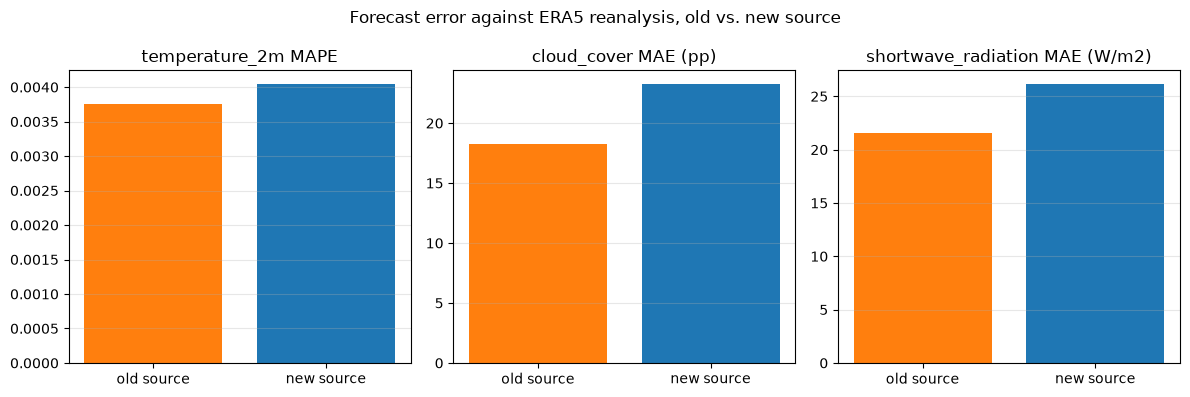

In [8]:
fig, axes = plt.subplots(1, len(summary), figsize=(12, 4))
for ax, (metric, row) in zip(axes, summary.iterrows()):
    ax.bar(["old source", "new source"], [row["pre_fix"], row["post_fix"]],
           color=["tab:orange", "tab:blue"])
    ax.set_title(metric)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("Forecast error against ERA5 reanalysis, old vs. new source")
fig.tight_layout()

## What this found

Across this sample window, `temperature_2m` MAPE, `cloud_cover` MAE and `shortwave_radiation` MAE all put the new source 7-22% harder than the old one. That confirms the reviewers' point: the old source was not a forecast. It was a near-real-time observation with a forecast's name on it.

Running this also surfaced a second bug. `winterload.source.openmeteo.MODELS` was built from the wrong `TypedDict`: `OpenMeteoModelResult.__annotations__`, which is just `["hourly"]`, instead of `OpenMeteoResult.__annotations__`, which is `["ecmwf_ifs"]`. Every call that passed `models=MODELS` got rejected by Open-Meteo outright, which is also why nobody had measured this gap before: the backfill could never complete a request. Fixed in `winterload/source/openmeteo.py:32`, with a regression test in `tests/source/test_openmeteo.py`.